###  ML Experiment Number 9
Student Name :Utkarsh Vishwanath Parulekar

Roll Number :CS39



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extendedThe Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:

# Load Mall Customer Segmentation Dataset

import pandas as pd
from google.colab import files

# Upload dataset
uploaded = files.upload()

# Load dataset
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display first five rows
print("Dataset loaded successfully!")
print(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())


Saving palmerpenguins_extended.csv to palmerpenguins_extended.csv
Dataset loaded successfully!
  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  

Dataset Shape: (3430, 11)

Column Names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', '

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:

# Task 2: Select Features and Target & Preprocess

import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Handle missing values
df = df.dropna().copy()

# Automatically identify column names
if 'culmen_length_mm' in df.columns:
    length_col = 'culmen_length_mm'
else:
    length_col = 'bill_length_mm'

if 'culmen_depth_mm' in df.columns:
    depth_col = 'culmen_depth_mm'
else:
    depth_col = 'bill_depth_mm'

# Select features
X = df[[length_col, depth_col,
        'flipper_length_mm', 'body_mass_g']]

# Select target
y = df['species']

# Encode target labels
le = LabelEncoder()
y = le.fit_transform(y)

# Display results
print("\nSelected Features:")
print(X.head())

print("\nEncoded Target:")
print(y[:5])

print("\nSpecies Classes:")
print(le.classes_)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Column Names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']

Selected Features:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            53.4           17.8              219.0       5687.0
1            49.3           18.1              245.0       6811.0
2            55.7           16.6              226.0       5388.0
3            38.0           15.6              221.0       6262.0
4            60.7           17.9              177.0       4811.0

Encoded Target:
[0 0 0 0 0]

Species Classes:
['Adelie' 'Chinstrap' 'Gentoo']

Feature Shape: (3430, 4)
Target Shape: (3430,)


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:

# Task 3: Split the Data

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display dataset sizes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nData split completed successfully!")


Training Features Shape: (2744, 4)
Testing Features Shape: (686, 4)
Training Target Shape: (2744,)
Testing Target Shape: (686,)

Data split completed successfully!


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:

# Task 4: Implement CART Classifier

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree Classifier
model = DecisionTreeClassifier(criterion='gini', random_state=42)

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Display predictions
print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred)

print("\nCART Classifier implemented successfully!")


Actual Values:
[0 2 0 0 0 2 1 0 2 0 0 0 0 0 2 2 2 2 0 0 1 0 1 1 0 0 0 1 0 2 0 2 0 2 2 0 0
 0 0 0 0 1 2 0 0 0 0 0 1 2 0 2 0 1 0 1 2 2 1 1 0 0 2 0 0 1 0 1 0 0 2 0 0 2
 0 0 0 2 0 2 2 0 0 0 1 2 0 0 1 1 0 2 0 2 2 0 1 2 1 0 1 1 2 1 2 0 0 0 2 2 2
 1 0 0 2 2 2 0 0 1 2 2 0 0 0 0 0 2 0 1 1 0 2 2 1 0 0 2 0 0 2 0 2 1 0 0 2 2
 0 1 0 2 2 0 0 0 2 0 1 1 1 0 2 0 2 0 2 0 0 1 1 1 0 1 0 0 2 0 2 0 2 0 2 0 0
 1 1 0 0 0 1 1 1 2 2 0 0 0 1 1 2 0 0 0 2 0 2 2 2 0 2 0 2 1 1 0 1 1 2 2 1 0
 2 2 2 2 0 0 0 0 0 2 1 2 0 0 2 2 0 1 2 0 2 0 2 2 2 0 2 0 1 1 0 2 0 2 0 0 0
 0 2 0 2 2 2 0 1 0 1 2 2 2 1 2 0 0 2 2 0 0 2 2 1 2 2 1 2 1 0 0 2 1 0 0 2 0
 2 1 2 2 0 2 0 2 2 2 0 0 0 2 0 0 2 2 0 0 0 1 2 2 1 2 2 2 1 1 1 0 0 0 1 0 2
 0 1 0 2 0 0 2 0 0 0 2 0 0 1 0 0 2 0 0 0 0 1 1 2 0 0 2 2 0 2 0 0 0 1 2 2 0
 2 1 1 0 0 0 0 0 0 0 2 1 1 1 0 1 1 0 2 0 2 2 2 0 0 0 2 0 2 2 0 0 2 0 2 0 2
 2 0 2 1 0 1 0 2 2 1 0 2 0 2 1 0 2 0 2 2 2 1 2 0 2 1 2 2 2 0 2 0 0 2 0 0 2
 2 0 0 1 0 1 1 0 0 2 1 0 2 2 2 0 2 0 2 2 0 2 2 2 0 0 1 1 2 0 2 2 0 0 0 2 0
 2 2 0 0 2

# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

Accuracy: 45.19 %

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]


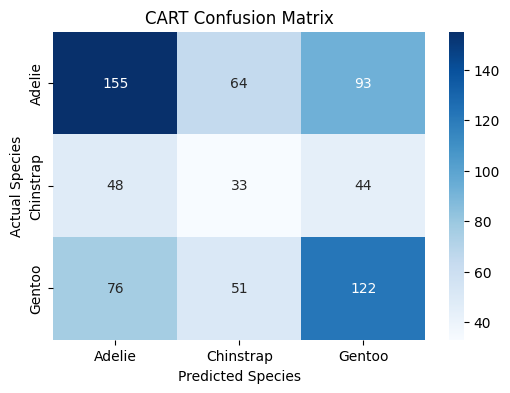


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



In [ ]:

# Task 5: Evaluate CART Model

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("CART Confusion Matrix")
plt.show()

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))


# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


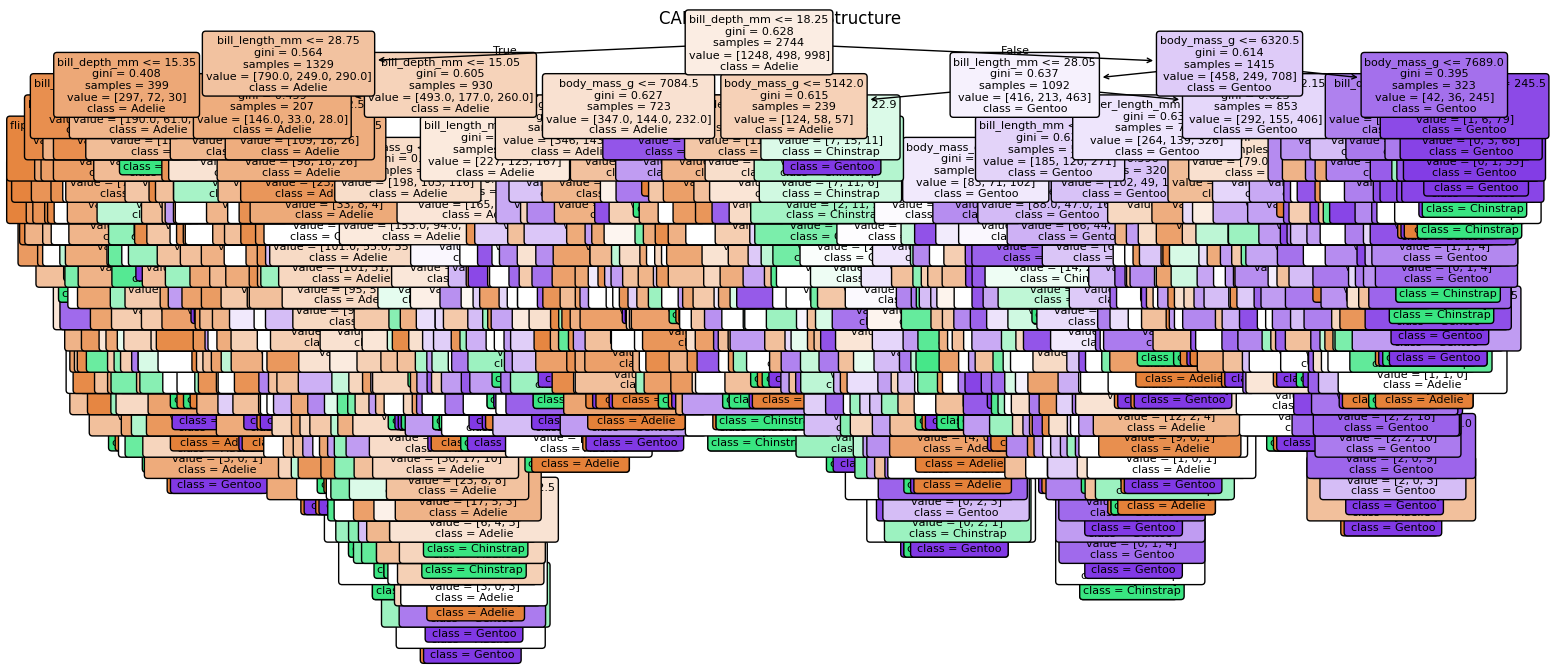

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


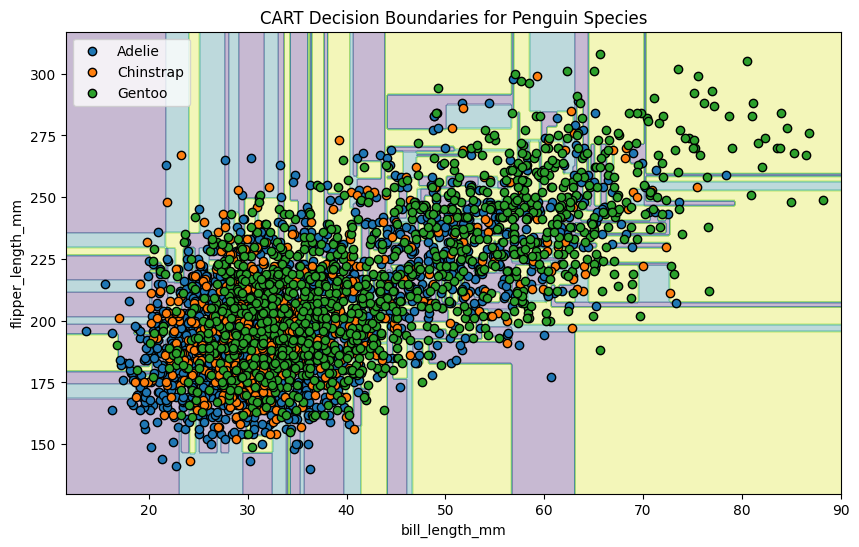

In [ ]:

# Task 6: Visualize Decision Tree & Decision Boundary

import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, DecisionTreeClassifier

# 1. Visualize the full Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("CART Decision Tree Structure")
plt.show()

# 2. Select 2-D features
X_2d = X[['bill_length_mm' if 'bill_length_mm' in X.columns
          else 'culmen_length_mm',
          'flipper_length_mm']]

# Split 2-D data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Train Decision Tree using 2-D features
model_2d = DecisionTreeClassifier(criterion='gini', random_state=42)
model_2d.fit(X_train_2d, y_train_2d)

# 4. Create a mesh grid
x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 10, X_2d.iloc[:, 1].max() + 10

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.2),
    np.arange(y_min, y_max, 1)
)

# Predict regions
Z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 5. Plot decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

# Plot data points
for i, species in enumerate(le.classes_):
    plt.scatter(
        X_2d.iloc[:, 0][y == i],
        X_2d.iloc[:, 1][y == i],
        label=species,
        edgecolors='black'
    )

plt.xlabel(X_2d.columns[0])
plt.ylabel('flipper_length_mm')
plt.title('CART Decision Boundaries for Penguin Species')
plt.legend()
plt.show()


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


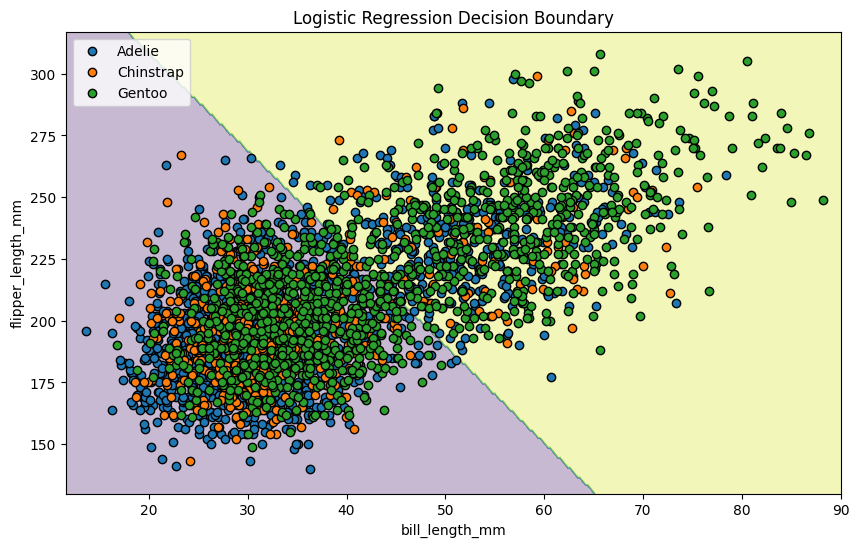

Logistic Regression Accuracy: 52.62 %


In [ ]:

# Task 7: Normal Linear Classification Boundary

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# Train Logistic Regression model
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_2d, y_train_2d)

# Create mesh grid
x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 10, X_2d.iloc[:, 1].max() + 10

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.2),
    np.arange(y_min, y_max, 1)
)

# Predict classes
Z = log_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

# Plot data points
for i, species in enumerate(le.classes_):
    plt.scatter(
        X_2d.iloc[:, 0][y == i],
        X_2d.iloc[:, 1][y == i],
        label=species,
        edgecolors='black'
    )

plt.xlabel(X_2d.columns[0])
plt.ylabel('flipper_length_mm')
plt.title('Logistic Regression Decision Boundary')
plt.legend()
plt.show()

# Evaluate model
print("Logistic Regression Accuracy:",
      round(log_model.score(X_test_2d, y_test_2d) * 100, 2), "%")


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


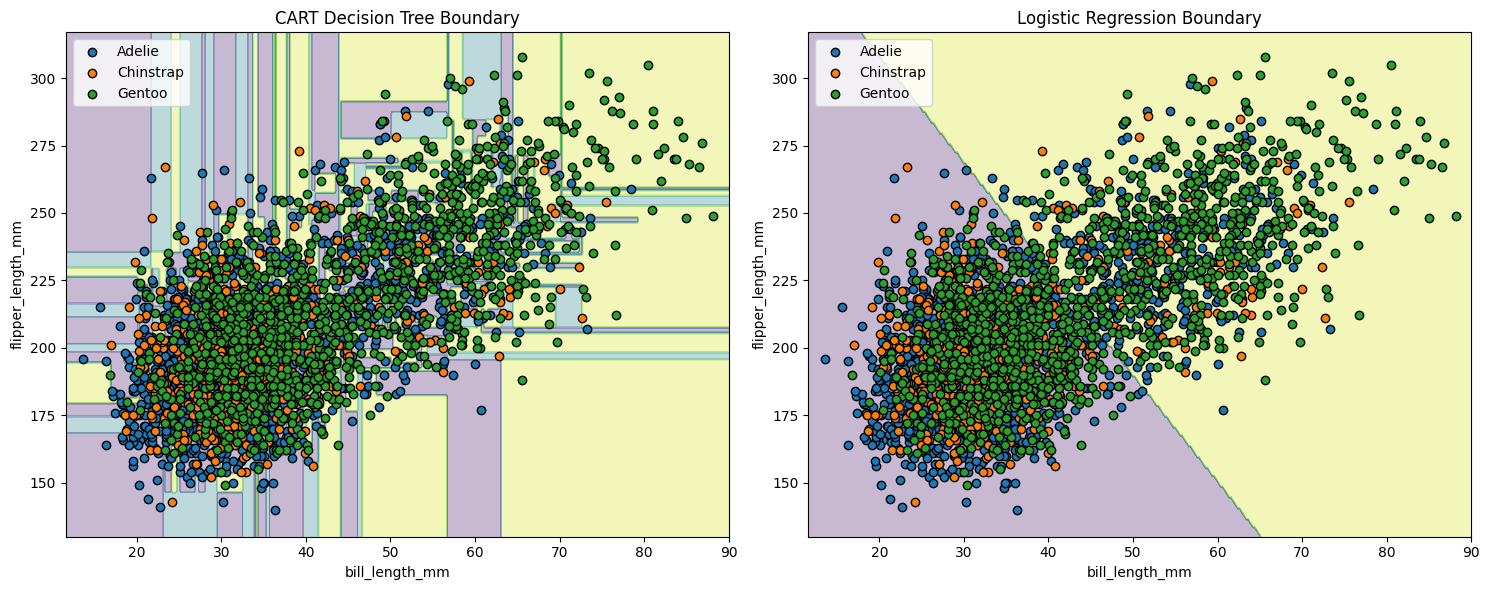

In [ ]:

# Task 8: Compare CART and Logistic Regression Boundaries

import numpy as np
import matplotlib.pyplot as plt

# Create mesh grid
x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 10, X_2d.iloc[:, 1].max() + 10

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.2),
    np.arange(y_min, y_max, 1)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Predict using both models
Z_tree = model_2d.predict(grid).reshape(xx.shape)
Z_log = log_model.predict(grid).reshape(xx.shape)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Decision Tree boundary
axes[0].contourf(xx, yy, Z_tree, alpha=0.3, cmap='viridis')
for i, species in enumerate(le.classes_):
    axes[0].scatter(
        X_2d.iloc[:, 0][y == i],
        X_2d.iloc[:, 1][y == i],
        label=species,
        edgecolors='black'
    )
axes[0].set_title("CART Decision Tree Boundary")
axes[0].set_xlabel(X_2d.columns[0])
axes[0].set_ylabel('flipper_length_mm')
axes[0].legend()

# Logistic Regression boundary
axes[1].contourf(xx, yy, Z_log, alpha=0.3, cmap='viridis')
for i, species in enumerate(le.classes_):
    axes[1].scatter(
        X_2d.iloc[:, 0][y == i],
        X_2d.iloc[:, 1][y == i],
        label=species,
        edgecolors='black'
    )
axes[1].set_title("Logistic Regression Boundary")
axes[1].set_xlabel(X_2d.columns[0])
axes[1].set_ylabel('flipper_length_mm')
axes[1].legend()

plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

CART Classifier Accuracy: 43.88 %
Logistic Regression Accuracy: 52.62 %

Accuracy Comparison:
                 Model  Accuracy (%)
0      CART Classifier         43.88
1  Logistic Regression         52.62


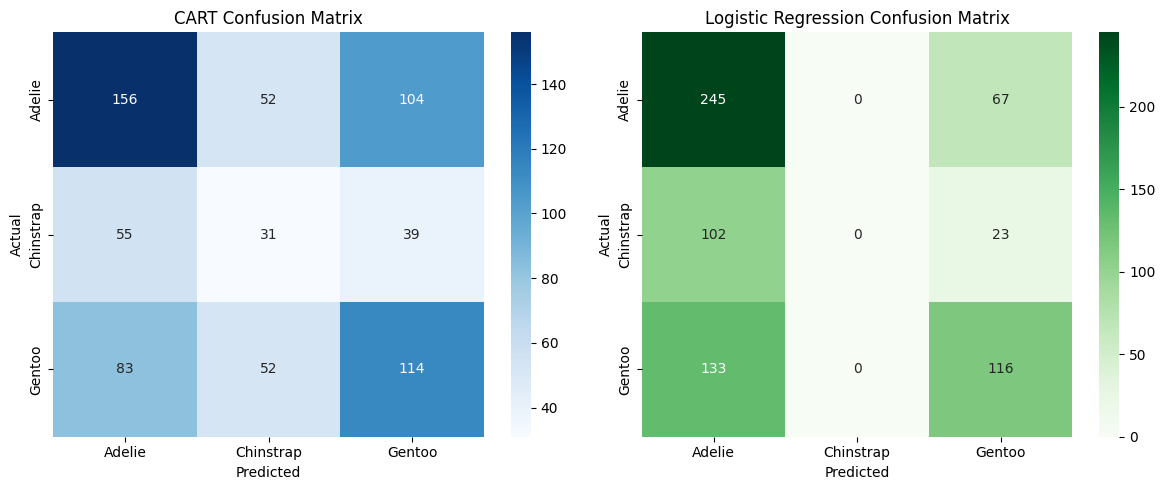


CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.53      0.50      0.51       312
   Chinstrap       0.23      0.25      0.24       125
      Gentoo       0.44      0.46      0.45       249

    accuracy                           0.44       686
   macro avg       0.40      0.40      0.40       686
weighted avg       0.44      0.44      0.44       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686



In [ ]:

# Task 9: Compare Performance

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Predictions from both models
y_pred_cart = model_2d.predict(X_test_2d)
y_pred_log = log_model.predict(X_test_2d)

# Calculate accuracy
cart_accuracy = accuracy_score(y_test_2d, y_pred_cart)
log_accuracy = accuracy_score(y_test_2d, y_pred_log)

print("CART Classifier Accuracy:", round(cart_accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:", round(log_accuracy * 100, 2), "%")

# Compare accuracy in a table
results = pd.DataFrame({
    'Model': ['CART Classifier', 'Logistic Regression'],
    'Accuracy (%)': [cart_accuracy * 100, log_accuracy * 100]
})

print("\nAccuracy Comparison:")
print(results.round(2))

# Confusion matrices
cm_cart = confusion_matrix(y_test_2d, y_pred_cart)
cm_log = confusion_matrix(y_test_2d, y_pred_log)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_, ax=axes[0])
axes[0].set_title("CART Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_log, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_,
            yticklabels=le.classes_, ax=axes[1])
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Classification reports
print("\nCART Classification Report:")
print(classification_report(
    y_test_2d, y_pred_cart, target_names=le.classes_, zero_division=0
))

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test_2d, y_pred_log, target_names=le.classes_, zero_division=0
))


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.